In [4]:
# @title Cell 1: Setup dan Pemuatan Data
import os
import sys
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

WORK_DIR = "/content/tugasAI_part2"
PLACEMENT = {
    "train.csv": "datasets",
    "test.csv": "datasets",
    "sample_submission.csv": "datasets",
    "pipeline.py": "preprocessing",
}

os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)


def missing_files():
    return [name for name, folder in PLACEMENT.items() if not os.path.exists(os.path.join(folder, name))]


if missing_files():
    from google.colab import files

    print("Pilih dan unggah file berikut sekaligus:", missing_files())
    for name in files.upload():
        if name in PLACEMENT:
            os.makedirs(PLACEMENT[name], exist_ok=True)
            shutil.move(name, os.path.join(PLACEMENT[name], name))
        else:
            print("File diabaikan karena tidak dikenal:", name)

if missing_files():
    raise FileNotFoundError(f"File belum lengkap: {missing_files()}")

sys.path.insert(0, WORK_DIR)

import preprocessing.pipeline as pl

DATA_DIR = "datasets"
SEED = pl.SEED
TARGET, ID_COL = pl.TARGET, pl.ID_COL
LABEL_MAP, CLASS_NAMES = pl.LABEL_MAP, pl.CLASS_NAMES
CU = pl.CU


def section(title, width=70):
    print("\n" + "=" * width + f"\n{title}\n" + "=" * width)


train_raw = pl.clean_column_names(pd.read_csv(f"{DATA_DIR}/train.csv"))
test_raw = pl.clean_column_names(pd.read_csv(f"{DATA_DIR}/test.csv"))
sample_submission = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

section("1.1 Ukuran dan konsistensi data")
feature_cols = [c for c in train_raw.columns if c != TARGET]
print("Shape train        :", train_raw.shape)
print("Shape test         :", test_raw.shape)
print("Shape submission   :", sample_submission.shape)
print("Kolom fitur train sama dengan test :", feature_cols == list(test_raw.columns))
print("Student_ID unik (train, test)      :", train_raw[ID_COL].is_unique, test_raw[ID_COL].is_unique)
print("Irisan ID train dan test           :", len(set(train_raw[ID_COL]) & set(test_raw[ID_COL])))
print("ID test sama dengan ID submission  :", set(test_raw[ID_COL]) == set(sample_submission[ID_COL]))
print("Nilai Target tidak dikenal         :", sorted(set(train_raw[TARGET]) - set(CLASS_NAMES)))

section("1.2 Kelompok kolom")
grouped = pl.NOMINAL_COLS + pl.NUMERIC_COLS + pl.BINARY_COLS
print("Nominal  :", len(pl.NOMINAL_COLS), "kolom")
print("Numerik  :", len(pl.NUMERIC_COLS), "kolom")
print("Biner    :", len(pl.BINARY_COLS), "kolom")
print("Semua fitur terkelompok :", sorted(grouped) == sorted(c for c in feature_cols if c != ID_COL))
print("Pemetaan label          :", LABEL_MAP)

Pilih dan unggah file berikut sekaligus: ['train.csv', 'test.csv', 'sample_submission.csv', 'pipeline.py']


Saving pipeline.py to pipeline.py
Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv

1.1 Ukuran dan konsistensi data
Shape train        : (3096, 38)
Shape test         : (1328, 37)
Shape submission   : (1328, 2)
Kolom fitur train sama dengan test : True
Student_ID unik (train, test)      : True True
Irisan ID train dan test           : 0
ID test sama dengan ID submission  : True
Nilai Target tidak dikenal         : []

1.2 Kelompok kolom
Nominal  : 9 kolom
Numerik  : 19 kolom
Biner    : 8 kolom
Semua fitur terkelompok : True
Pemetaan label          : {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}



2.1 Distribusi target
          jumlah  persen
Target                  
Graduate    1546   49.94
Dropout      994   32.11
Enrolled     556   17.96

Rasio kelas mayoritas : minoritas = 2.78 : 1


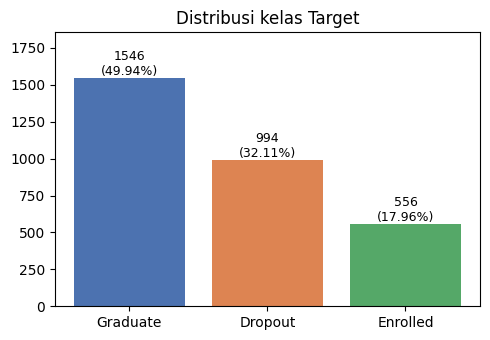


2.2 Kardinalitas kolom nominal
Father's occupation       40
Father's qualification    32
Mother's occupation       31
Mother's qualification    28
Application mode          18
Course                    17
Nationality               17
Previous qualification    17
Marital status             6

Fitur sebelum one-hot : 36
Fitur sesudah one-hot : 233 (nominal 206 + lainnya 27)
Angka ini dihitung dari seluruh train; setelah split dan fit pada train bisa sedikit lebih kecil.

2.3 Ringkasan kolom numerik
                                    min  median     max  skew  %out_1.5IQR  %out_3IQR
Previous qualification (grade)    95.00  133.10  190.00  0.30         3.75       0.10
Admission grade                   95.00  126.00  190.00  0.53         1.84       0.10
Age at enrollment                 17.00   20.00   70.00  2.08         9.92       3.39
CU 1st sem (credited)              0.00    0.00   20.00  4.19        13.21      13.21
CU 1st sem (enrolled)              0.00    6.00   26.00  1.59      

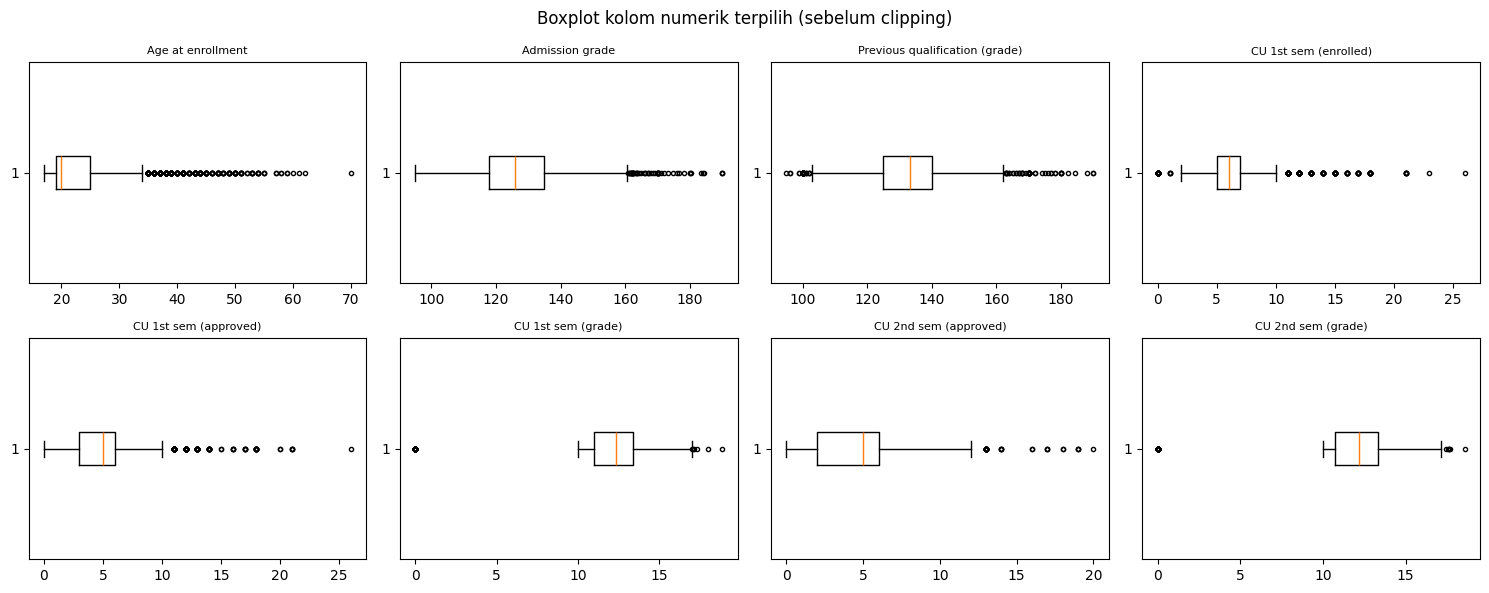


2.4 Korelasi antar fitur akademik
                               level_0                                level_1  corr
   Curricular units 1st sem (credited)    Curricular units 2nd sem (credited) 0.951
   Curricular units 1st sem (enrolled)    Curricular units 2nd sem (enrolled) 0.946
   Curricular units 1st sem (approved)    Curricular units 2nd sem (approved) 0.904
      Curricular units 1st sem (grade)       Curricular units 2nd sem (grade) 0.838
Curricular units 1st sem (evaluations) Curricular units 2nd sem (evaluations) 0.775
   Curricular units 1st sem (enrolled)    Curricular units 1st sem (approved) 0.770
   Curricular units 1st sem (credited)    Curricular units 1st sem (enrolled) 0.768
   Curricular units 2nd sem (approved)       Curricular units 2nd sem (grade) 0.765

Pasangan dengan |r| > 0.85: 3 dari 66
Fitur semester 1 dan 2 sangat berkorelasi, ini dasar tahap pembuangan redundansi pada seleksi fitur.


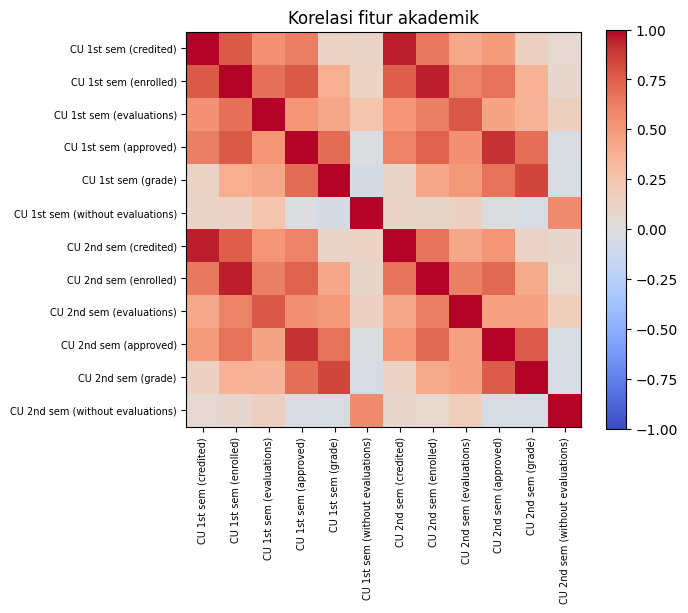

In [5]:
# @title Cell 2: Exploratory Data Analysis
section("2.1 Distribusi target")
counts = train_raw[TARGET].value_counts()
percent = (counts / counts.sum() * 100).round(2)
print(pd.DataFrame({"jumlah": counts, "persen": percent}))
print(f"\nRasio kelas mayoritas : minoritas = {counts.max() / counts.min():.2f} : 1")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(counts.index, counts.values, color=["#4c72b0", "#dd8452", "#55a868"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v}\n({percent.iloc[i]}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Distribusi kelas Target")
plt.tight_layout()
plt.show()

section("2.2 Kardinalitas kolom nominal")
cardinality = train_raw[pl.NOMINAL_COLS].nunique().sort_values(ascending=False)
n_other = len(pl.BINARY_COLS) + len(pl.NUMERIC_COLS)
print(cardinality.to_string())
print(f"\nFitur sebelum one-hot : {len(pl.NOMINAL_COLS) + n_other}")
print(f"Fitur sesudah one-hot : {int(cardinality.sum()) + n_other} (nominal {int(cardinality.sum())} + lainnya {n_other})")
print("Angka ini dihitung dari seluruh train; setelah split dan fit pada train bisa sedikit lebih kecil.")

section("2.3 Ringkasan kolom numerik")
numeric = train_raw[pl.NUMERIC_COLS]
q1, q3 = numeric.quantile(0.25), numeric.quantile(0.75)
iqr = q3 - q1
summary = pd.DataFrame({
    "min": numeric.min(), "median": numeric.median(), "max": numeric.max(),
    "skew": numeric.skew(),
    "%out_1.5IQR": ((numeric < q1 - 1.5 * iqr) | (numeric > q3 + 1.5 * iqr)).mean() * 100,
    "%out_3IQR": ((numeric < q1 - 3.0 * iqr) | (numeric > q3 + 3.0 * iqr)).mean() * 100,
}).round(2)
summary.index = [c.replace(CU, "CU") for c in summary.index]
print(summary.to_string())

show = [
    "Age at enrollment", "Admission grade", "Previous qualification (grade)",
    f"{CU} 1st sem (enrolled)", f"{CU} 1st sem (approved)", f"{CU} 1st sem (grade)",
    f"{CU} 2nd sem (approved)", f"{CU} 2nd sem (grade)",
]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), show):
    ax.boxplot(train_raw[col], vert=False, flierprops=dict(markersize=3))
    ax.set_title(col.replace(CU, "CU"), fontsize=8)
plt.suptitle("Boxplot kolom numerik terpilih (sebelum clipping)")
plt.tight_layout()
plt.show()

section("2.4 Korelasi antar fitur akademik")
academic = [c for c in pl.NUMERIC_COLS if c.startswith(CU)]
corr = train_raw[academic].corr()
pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack().rename("corr").reset_index()
    .assign(abs_corr=lambda d: d["corr"].abs())
    .sort_values("abs_corr", ascending=False)
)
print(pairs.head(8)[["level_0", "level_1", "corr"]].round(3).to_string(index=False))
print(f"\nPasangan dengan |r| > 0.85: {(pairs['abs_corr'] > 0.85).sum()} dari {len(pairs)}")
print("Fitur semester 1 dan 2 sangat berkorelasi, ini dasar tahap pembuangan redundansi pada seleksi fitur.")

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
labels = [c.replace("Curricular units ", "CU ") for c in academic]
ax.set_xticks(range(len(academic)))
ax.set_yticks(range(len(academic)))
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_yticklabels(labels, fontsize=7)
plt.colorbar(image)
ax.set_title("Korelasi fitur akademik")
plt.tight_layout()
plt.show()

In [6]:
# @title Cell 3: Data Cleaning dan Split Train-Validasi
from sklearn.model_selection import train_test_split

section("3.1 Audit kualitas data")
duplicates_train = int(train_raw.drop(columns=ID_COL).duplicated().sum())
duplicates_test = int(test_raw.drop(columns=ID_COL).duplicated().sum())
X_train_all, flagged_train = pl.clean_values(train_raw.drop(columns=[ID_COL, TARGET]))
X_test_all, flagged_test = pl.clean_values(test_raw.drop(columns=ID_COL))

groups = {
    "Nilai di luar rentang (grade, usia, application order)": ["di luar 0-200", "di luar 0-20", "di luar 17-70", "di luar 0-9"],
    "Approved melebihi enrolled + credited": ["melebihi enrolled + credited"],
    "Nilai negatif pada kolom hitungan": ["negatif"],
    "Nilai biner di luar 0/1": ["di luar 0/1"],
}


def count_rule(flags, suffixes):
    return sum(v for k, v in flags.items() if any(k.endswith(s) for s in suffixes))


audit = pd.DataFrame({
    "train": {name: count_rule(flagged_train, s) for name, s in groups.items()},
    "test": {name: count_rule(flagged_test, s) for name, s in groups.items()},
})
audit.loc["Baris duplikat (tanpa ID)"] = [duplicates_train, duplicates_test]
audit.loc["Missing value awal"] = [int(train_raw.isna().sum().sum()), int(test_raw.isna().sum().sum())]
print(audit.to_string())
print("\nKeterangan: setiap aturan di atas memeriksa nilai yang mustahil menurut logika domain.")
if audit.values.sum() == 0:
    print("Tidak ada temuan, jadi tidak ada baris dibuang dan tidak ada nilai yang perlu diimputasi.")
    print("Pipeline tetap menyiapkan penanganannya (tandai sebagai kosong, lalu imputasi median atau modus dari train) sebagai pengaman.")
else:
    print("Ada temuan: nilainya dijadikan kosong lalu diimputasi dengan median atau modus dari data train.")

section("3.2 Pemisahan fitur, label, dan identitas")
y_all = train_raw[TARGET].map(LABEL_MAP).astype(int).values
id_all = train_raw[ID_COL].values
id_test = test_raw[ID_COL].values
print("Fitur train :", X_train_all.shape, "| Label :", y_all.shape)
print("Fitur test  :", X_test_all.shape)

section("3.3 Split train dan validasi (stratified, sebelum langkah fit apa pun)")
train_idx, val_idx = train_test_split(np.arange(len(y_all)), test_size=0.20, stratify=y_all, random_state=SEED)
X_train_raw = X_train_all.iloc[train_idx].reset_index(drop=True)
X_val_raw = X_train_all.iloc[val_idx].reset_index(drop=True)
y_train, y_val = y_all[train_idx], y_all[val_idx]

distribution = pd.DataFrame({
    "train": np.bincount(y_train), "train_%": (np.bincount(y_train) / len(y_train) * 100).round(2),
    "validasi": np.bincount(y_val), "validasi_%": (np.bincount(y_val) / len(y_val) * 100).round(2),
    "seluruh_%": (np.bincount(y_all) / len(y_all) * 100).round(2),
}, index=CLASS_NAMES)
print(distribution.to_string())
print(f"\nUkuran train {len(X_train_raw)} | validasi {len(X_val_raw)} | test {len(X_test_all)} (tidak disentuh)")

assert len(set(id_all[train_idx]) & set(id_all[val_idx])) == 0
assert len(train_idx) + len(val_idx) == len(id_all)
print("Verifikasi: tidak ada irisan ID antara train dan validasi, dan seluruh baris terpakai.")

section("3.4 Imputer pengaman (di-fit hanya pada train)")
imputer = pl.TrainImputer().fit(X_train_raw)
print("Sel kosong (train, validasi, test):",
      imputer.count_missing(X_train_raw), imputer.count_missing(X_val_raw), imputer.count_missing(X_test_all))
X_train_raw = imputer.transform(X_train_raw)
X_val_raw = imputer.transform(X_val_raw)
X_test_raw = imputer.transform(X_test_all)


3.1 Audit kualitas data
                                                        train  test
Nilai di luar rentang (grade, usia, application order)      0     0
Approved melebihi enrolled + credited                       0     0
Nilai negatif pada kolom hitungan                           0     0
Nilai biner di luar 0/1                                     0     0
Baris duplikat (tanpa ID)                                   0     0
Missing value awal                                          0     0

Keterangan: setiap aturan di atas memeriksa nilai yang mustahil menurut logika domain.
Tidak ada temuan, jadi tidak ada baris dibuang dan tidak ada nilai yang perlu diimputasi.
Pipeline tetap menyiapkan penanganannya (tandai sebagai kosong, lalu imputasi median atau modus dari train) sebagai pengaman.

3.2 Pemisahan fitur, label, dan identitas
Fitur train : (3096, 36) | Label : (3096,)
Fitur test  : (1328, 36)

3.3 Split train dan validasi (stratified, sebelum langkah fit apa pun)
          tr


4.1 Nol struktural pada kolom numerik (data train)
Semester 1st: 16.16% baris bernilai grade = 0 | enrolled = 0 pada  26.8%, approved = 0 pada 100.0%
Semester 2nd: 19.71% baris bernilai grade = 0 | enrolled = 0 pada  21.9%, approved = 0 pada 100.0%

                                   %nol  %out_semua  %out_tanpa_nol
kolom                                                              
Previous qualification (grade)     0.00        3.84            3.84
Admission grade                    0.00        1.86            1.86
Age at enrollment                  0.00       10.14           10.14
CU 1st sem (credited)             86.71       13.29            3.95
CU 1st sem (enrolled)              4.32        9.94            8.95
CU 1st sem (evaluations)           8.28        3.51            3.04
CU 1st sem (approved)             16.16        4.00            5.64
CU 1st sem (grade)                16.16       16.40            0.96
CU 1st sem (without evaluations)  92.97        7.03           13.22
C

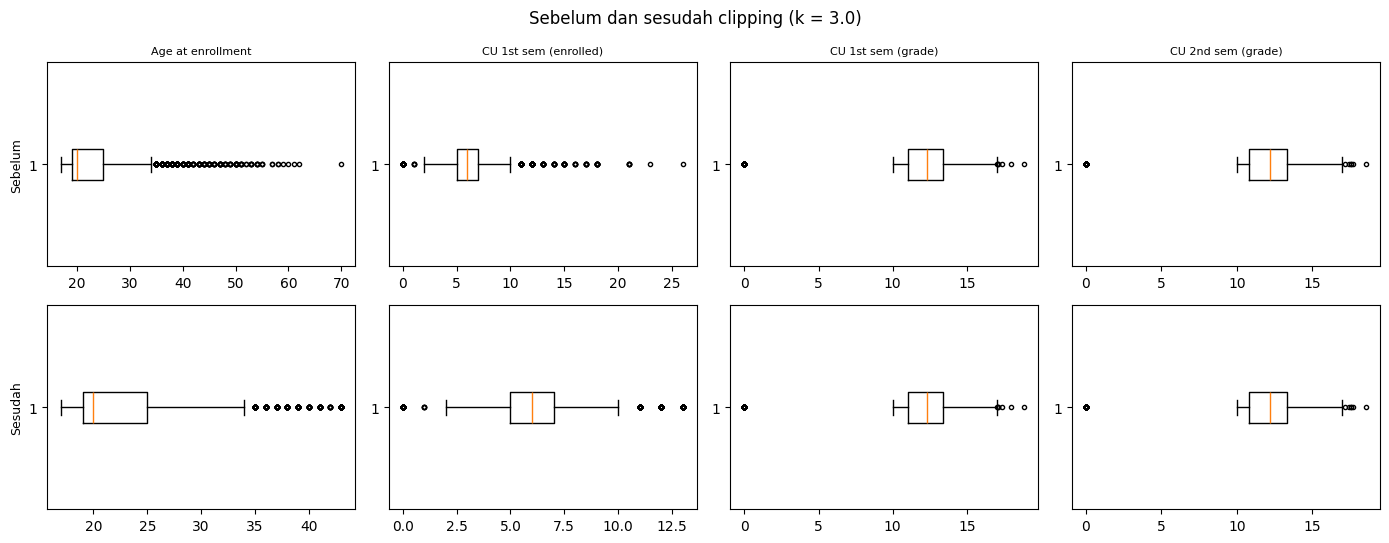

In [7]:
# @title Cell 4: Deteksi dan Penanganan Outlier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

section("4.1 Nol struktural pada kolom numerik (data train)")
for sem in ["1st", "2nd"]:
    zero_grade = X_train_raw[f"{CU} {sem} sem (grade)"] == 0
    rows = X_train_raw.loc[zero_grade]
    print(f"Semester {sem}: {zero_grade.mean() * 100:5.2f}% baris bernilai grade = 0 | "
          f"enrolled = 0 pada {(rows[f'{CU} {sem} sem (enrolled)'] == 0).mean() * 100:5.1f}%, "
          f"approved = 0 pada {(rows[f'{CU} {sem} sem (approved)'] == 0).mean() * 100:5.1f}%")

records = []
for col in pl.NUMERIC_COLS:
    values = X_train_raw[col]
    q1, q3 = values.quantile([0.25, 0.75])
    nonzero = values[values != 0]
    q1n, q3n = nonzero.quantile([0.25, 0.75])
    records.append({
        "kolom": col.replace(CU, "CU"),
        "%nol": (values == 0).mean() * 100,
        "%out_semua": ((values < q1 - 1.5 * (q3 - q1)) | (values > q3 + 1.5 * (q3 - q1))).mean() * 100,
        "%out_tanpa_nol": ((nonzero < q1n - 1.5 * (q3n - q1n)) | (nonzero > q3n + 1.5 * (q3n - q1n))).mean() * 100,
    })
zero_table = pd.DataFrame(records).set_index("kolom").round(2)
print("\n" + zero_table.to_string())
print("\nKeterangan: pada kolom grade, nilai 0 berarti mahasiswa tidak mengikuti penilaian, bukan nilai ekstrem.")
print("Karena itu batas outlier kolom grade dihitung dari nilai tidak nol, dan nilai nol dibiarkan.")

section("4.2 Keputusan per kolom")
skipped = [c for c in pl.NUMERIC_COLS if c not in pl.CLIP_STANDARD + pl.CLIP_ZERO_AWARE]
print(f"Clip standar   ({len(pl.CLIP_STANDARD)}):", [c.replace(CU, "CU") for c in pl.CLIP_STANDARD])
print(f"Clip sadar-nol ({len(pl.CLIP_ZERO_AWARE)}):", [c.replace(CU, "CU") for c in pl.CLIP_ZERO_AWARE])
print(f"Tidak di-clip  ({len(skipped)}):", [c.replace(CU, "CU") for c in skipped])

section("4.3 Jumlah sel terpotong untuk tiap pengali IQR")
K_GRID = [1.5, 2.0, 3.0]
clipped = {}
for k in K_GRID:
    probe = pl.OutlierClipper(k=k).fit(X_train_raw)
    clipped[f"k={k}"] = probe.count_clipped(X_train_raw)
total_cells = len(X_train_raw) * len(pl.CLIP_STANDARD + pl.CLIP_ZERO_AWARE)
print(pd.Series(clipped).to_frame("sel terpotong (train)").to_string())
print(f"dari {total_cells} sel pada kolom yang di-clip")

section("4.4 Pemilihan pengali IQR dengan 5-fold CV pada train (Macro F1)")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_eval_pipeline(k):
    encoder = ColumnTransformer([
        ("nominal", OneHotEncoder(handle_unknown="ignore"), pl.NOMINAL_COLS),
        ("numeric", StandardScaler(), pl.NUMERIC_COLS),
    ], remainder="passthrough")
    return Pipeline([
        ("clip", pl.OutlierClipper(k=k)),
        ("encode", encoder),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
    ])


results = {}
for name, k in [("tanpa clipping", np.inf)] + [(f"k = {k}", k) for k in K_GRID]:
    scores = cross_val_score(make_eval_pipeline(k), X_train_raw, y_train, cv=cv, scoring="f1_macro")
    results[name] = {"F1 rata-rata": scores.mean(), "std": scores.std(), "min": scores.min(), "max": scores.max()}
k_table = pd.DataFrame(results).T.round(4)
print(k_table.to_string())
spread = k_table["F1 rata-rata"].max() - k_table["F1 rata-rata"].min()
noise = k_table["std"].mean()
print(f"\nRentang antar opsi {spread:.4f}, simpangan baku antar fold {noise:.4f}")
if spread < noise:
    print("Perbedaan antar opsi lebih kecil dari derau antar fold, jadi pilihan k tidak menentukan hasil.")
    print("Dipilih k = 3.0 karena paling konservatif (hanya memotong nilai yang benar-benar ekstrem).")
else:
    print("Ada perbedaan antar opsi yang melampaui derau antar fold, tinjau tabel sebelum memilih k.")

section("4.5 Clipper final (fit hanya pada train)")
K_FINAL = 3.0
clipper = pl.OutlierClipper(k=K_FINAL).fit(X_train_raw)
X_train_clip = clipper.transform(X_train_raw)
X_val_clip = clipper.transform(X_val_raw)
X_test_clip = clipper.transform(X_test_raw)
bounds = pd.DataFrame(clipper.bounds_, index=["batas bawah", "batas atas"]).T
bounds.index = [c.replace(CU, "CU") for c in bounds.index]
print(bounds.round(2).to_string())
print("\nTotal sel terpotong pada train:", clipper.count_clipped(X_train_raw))

show = ["Age at enrollment", f"{CU} 1st sem (enrolled)", f"{CU} 1st sem (grade)", f"{CU} 2nd sem (grade)"]
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for j, col in enumerate(show):
    axes[0, j].boxplot(X_train_raw[col], vert=False, flierprops=dict(markersize=3))
    axes[0, j].set_title(col.replace(CU, "CU"), fontsize=8)
    axes[1, j].boxplot(X_train_clip[col], vert=False, flierprops=dict(markersize=3))
axes[0, 0].set_ylabel("Sebelum", fontsize=9)
axes[1, 0].set_ylabel("Sesudah", fontsize=9)
plt.suptitle(f"Sebelum dan sesudah clipping (k = {K_FINAL})")
plt.tight_layout()
plt.show()


5.1 Encoding dan standardisasi (fit hanya pada train)
Nominal : one-hot (kode pada kolom nominal adalah label, bukan urutan)
Numerik : standardisasi z-score (penting untuk KNN, Logistic Regression, dan ANN)
Biner   : dipakai apa adanya

Bentuk setelah encoding: (2476, 226) (620, 226) (1328, 226)
Rata-rata kolom numerik pada train (harus mendekati 0): 0.0
Rata-rata kolom numerik pada validasi (tidak harus 0, bukti statistik hanya dari train): 0.0726

5.2 Perbandingan jumlah fitur dengan 5-fold CV pada train (Macro F1)
                                        F1 rata-rata     std
tanpa seleksi                                 0.7049  0.0070
filter saja (dukungan, MI, redundansi)        0.7063  0.0164
top-10 MI                                     0.6945  0.0146
top-15 MI                                     0.6950  0.0217
top-20 MI                                     0.6995  0.0143
top-30 MI                                     0.7064  0.0203
top-45 MI                                     0.7

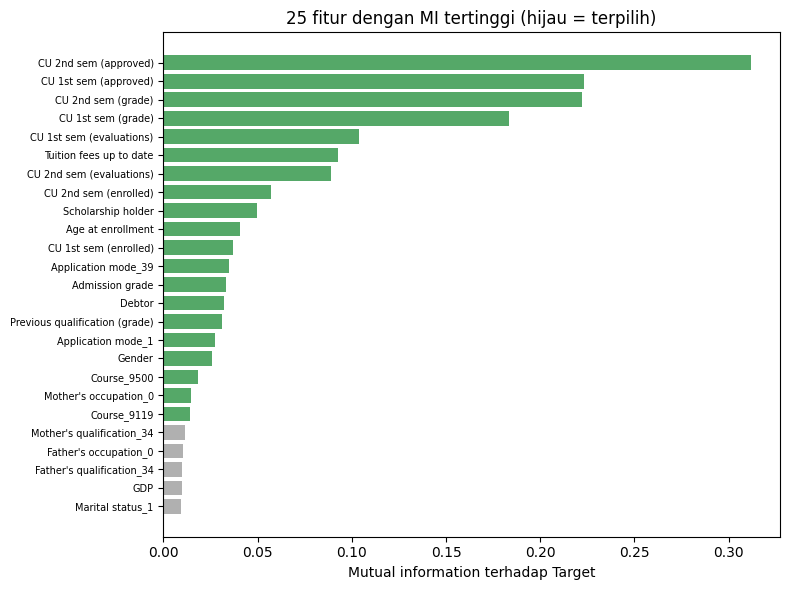

In [8]:
# @title Cell 5: Encoding, Standardisasi, dan Seleksi Fitur
from sklearn.metrics import f1_score


def make_encoder():
    encoder = ColumnTransformer([
        ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), pl.NOMINAL_COLS),
        ("numeric", StandardScaler(), pl.NUMERIC_COLS),
        ("binary", "passthrough", pl.BINARY_COLS),
    ])
    encoder.set_output(transform="pandas")
    return encoder


def encode(encoder, *frames):
    outputs = []
    for frame in frames:
        encoded = encoder.transform(frame)
        encoded.columns = [name.split("__", 1)[1] for name in encoded.columns]
        outputs.append(encoded)
    return outputs


section("5.1 Encoding dan standardisasi (fit hanya pada train)")
encoder = make_encoder().fit(X_train_clip)
X_train_enc, X_val_enc, X_test_enc = encode(encoder, X_train_clip, X_val_clip, X_test_clip)
print("Nominal : one-hot (kode pada kolom nominal adalah label, bukan urutan)")
print("Numerik : standardisasi z-score (penting untuk KNN, Logistic Regression, dan ANN)")
print("Biner   : dipakai apa adanya")
print("\nBentuk setelah encoding:", X_train_enc.shape, X_val_enc.shape, X_test_enc.shape)
numeric_after = [c for c in pl.NUMERIC_COLS]
print("Rata-rata kolom numerik pada train (harus mendekati 0):", round(float(X_train_enc[numeric_after].mean().abs().max()), 6))
print("Rata-rata kolom numerik pada validasi (tidak harus 0, bukti statistik hanya dari train):",
      round(float(X_val_enc[numeric_after].mean().abs().max()), 4))

section("5.2 Perbandingan jumlah fitur dengan 5-fold CV pada train (Macro F1)")
fold_data = []
for tr, va in cv.split(X_train_raw, y_train):
    part_a, part_b = X_train_raw.iloc[tr], X_train_raw.iloc[va]
    fold_clipper = pl.OutlierClipper(k=K_FINAL).fit(part_a)
    clipped_a, clipped_b = fold_clipper.transform(part_a), fold_clipper.transform(part_b)
    fold_encoder = make_encoder().fit(clipped_a)
    enc_a, enc_b = encode(fold_encoder, clipped_a, clipped_b)
    fold_selector = pl.FeatureSelector(n_features=None).fit(enc_a, y_train[tr])
    fold_data.append((enc_a, y_train[tr], enc_b, y_train[va], fold_selector.selected_))


def cv_score(choose_columns):
    scores = []
    for enc_a, ya, enc_b, yb, ranked in fold_data:
        columns = choose_columns(enc_a, ranked)
        model = LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)
        model.fit(enc_a[columns], ya)
        scores.append(f1_score(yb, model.predict(enc_b[columns]), average="macro"))
    return {"F1 rata-rata": np.mean(scores), "std": np.std(scores)}


N_GRID = [10, 15, 20, 30, 45, 60, 90]
selection = {
    "tanpa seleksi": cv_score(lambda enc, ranked: list(enc.columns)),
    "filter saja (dukungan, MI, redundansi)": cv_score(lambda enc, ranked: ranked),
}
for n in N_GRID:
    selection[f"top-{n} MI"] = cv_score(lambda enc, ranked, n=n: ranked[:n])
selection_table = pd.DataFrame(selection).T.round(4)
print(selection_table.to_string())

base_mean = selection_table.loc["tanpa seleksi", "F1 rata-rata"]
base_std = selection_table.loc["tanpa seleksi", "std"]
threshold = base_mean - base_std
top_rows = selection_table.loc[[i for i in selection_table.index if i.startswith("top-")]]
N_FINAL = min(int(i.split("-")[1].split()[0]) for i in top_rows.index if top_rows.loc[i, "F1 rata-rata"] >= threshold)
print(f"\nAturan: pilih jumlah fitur terkecil yang skornya tidak kurang dari skor tanpa seleksi dikurangi std-nya")
print(f"Ambang = {base_mean:.4f} - {base_std:.4f} = {threshold:.4f}")
print(f"Jumlah fitur terpilih: N_FINAL = {N_FINAL}")

section("5.3 Seleksi fitur final (fit hanya pada train)")
selector = pl.FeatureSelector(n_features=N_FINAL).fit(X_train_enc, y_train)
for stage, count in selector.stage_counts_.items():
    print(f"  {stage:28s}: {count}")
X_train_sel = selector.transform(X_train_enc)
X_val_sel = selector.transform(X_val_enc)
X_test_sel = selector.transform(X_test_enc)
print("\nBentuk akhir:", X_train_sel.shape, X_val_sel.shape, X_test_sel.shape)


def source_column(feature):
    for col in pl.NOMINAL_COLS:
        if feature.startswith(col + "_"):
            return col
    return feature


origin = pd.Series([source_column(f) for f in selector.selected_]).value_counts()
print(f"\n{len(selector.selected_)} fitur terpilih berasal dari {len(origin)} kolom asli:")
print(origin.to_string())

top = selector.mi_.head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(top)), top.values, color=["#55a868" if f in selector.selected_ else "#b0b0b0" for f in top.index])
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f.replace(CU, "CU") for f in top.index], fontsize=7)
ax.set_xlabel("Mutual information terhadap Target")
ax.set_title("25 fitur dengan MI tertinggi (hijau = terpilih)")
plt.tight_layout()
plt.show()

In [9]:
# @title Cell 6: Penanganan Imbalance (Oversampling hanya pada Train)
from sklearn.metrics import recall_score
from sklearn.neural_network import MLPClassifier

section("6.1 Perbandingan strategi imbalance dengan 5-fold CV pada train")


def run_scenario(make_model, oversample):
    rows = []
    for enc_a, ya, enc_b, yb, ranked in fold_data:
        columns = ranked[:N_FINAL]
        X_fit, y_fit = enc_a[columns].values, ya
        if oversample:
            order = pl.oversample_indices(ya)
            X_fit, y_fit = X_fit[order], ya[order]
        pred = make_model().fit(X_fit, y_fit).predict(enc_b[columns].values)
        enrolled = LABEL_MAP["Enrolled"]
        rows.append([
            f1_score(yb, pred, average="macro"),
            f1_score(yb, pred, average=None)[enrolled],
            recall_score(yb, pred, average=None)[enrolled],
        ])
    rows = np.array(rows)
    return {"Macro F1": rows[:, 0].mean(), "std": rows[:, 0].std(),
            "F1 Enrolled": rows[:, 1].mean(), "Recall Enrolled": rows[:, 2].mean()}


lr_plain = lambda: LogisticRegression(max_iter=3000, random_state=SEED)
lr_balanced = lambda: LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)
mlp = lambda: MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=SEED)

imbalance = {
    "LR tanpa penanganan": run_scenario(lr_plain, False),
    "LR class_weight=balanced": run_scenario(lr_balanced, False),
    "LR oversampling": run_scenario(lr_plain, True),
    "MLP tanpa penanganan": run_scenario(mlp, False),
    "MLP oversampling": run_scenario(mlp, True),
}
imbalance_table = pd.DataFrame(imbalance).T.round(4)
print(imbalance_table.to_string())
print("\nKeterangan: Recall Enrolled menunjukkan seberapa banyak mahasiswa Enrolled (kelas paling sedikit) yang berhasil ditemukan.")
print("MLPClassifier tidak mendukung class_weight, jadi oversampling adalah satu-satunya cara yang sama untuk versi from scratch dan scikit-learn.")

section("6.2 Oversampling final (hanya data train)")
resample_idx = pl.oversample_indices(y_train)
X_train_res = X_train_sel.values[resample_idx]
y_train_res = y_train[resample_idx]
comparison = pd.DataFrame({
    "train sebelum": np.bincount(y_train),
    "train sesudah": np.bincount(y_train_res),
    "validasi (tidak diubah)": np.bincount(y_val),
}, index=CLASS_NAMES)
print(comparison.to_string())
print(f"\nBentuk train: {X_train_sel.shape} -> {X_train_res.shape}")
print("Kelas minoritas diambil ulang dengan pengembalian sampai sama dengan kelas mayoritas. Validasi dan test tidak disentuh.")


6.1 Perbandingan strategi imbalance dengan 5-fold CV pada train
                          Macro F1     std  F1 Enrolled  Recall Enrolled
LR tanpa penanganan         0.6677  0.0131       0.3743           0.3056
LR class_weight=balanced    0.6995  0.0143       0.5046           0.6360
LR oversampling             0.6991  0.0164       0.5024           0.6315
MLP tanpa penanganan        0.6727  0.0173       0.3984           0.3640
MLP oversampling            0.6743  0.0172       0.4449           0.5056

Keterangan: Recall Enrolled menunjukkan seberapa banyak mahasiswa Enrolled (kelas paling sedikit) yang berhasil ditemukan.
MLPClassifier tidak mendukung class_weight, jadi oversampling adalah satu-satunya cara yang sama untuk versi from scratch dan scikit-learn.

6.2 Oversampling final (hanya data train)
          train sebelum  train sesudah  validasi (tidak diubah)
Dropout             795           1236                      199
Enrolled            445           1236                      11

In [10]:
# @title Cell 7: Pipeline Akhir dan Verifikasi Bebas Leakage
import shutil
import tempfile

section("7.1 Menjalankan pipeline akhir (preprocessing/pipeline.py)")
data = pl.build_dataset(DATA_DIR)
for key, value in data.report.items():
    print(f"{key} : {value}")
print("\nFitur terpilih:", data.feature_names)

section("7.2 Konsistensi dengan langkah manual di Cell 3 sampai 6")
checks = {
    "fitur terpilih sama": data.feature_names == list(selector.selected_),
    "X_train (oversampling) sama": np.allclose(data.X_train, X_train_res),
    "y_train sama": np.array_equal(data.y_train, y_train_res),
    "X_val sama": np.allclose(data.X_val, X_val_sel.values),
    "y_val sama": np.array_equal(data.y_val, y_val),
    "X_test sama": np.allclose(data.X_test, X_test_sel.values),
}
for name, passed in checks.items():
    print(f"  {name:30s}: {passed}")
assert all(checks.values())

section("7.3 Uji bebas leakage")
temp_dir = tempfile.mkdtemp()
shutil.copy(f"{DATA_DIR}/train.csv", f"{temp_dir}/train.csv")
altered_test = pd.read_csv(f"{DATA_DIR}/test.csv").iloc[:400].copy()
altered_test["Admission grade"] = 500.0
altered_test["Age at enrollment"] = 99
altered_test.to_csv(f"{temp_dir}/test.csv", index=False)
altered = pl.build_dataset(temp_dir)
shutil.rmtree(temp_dir)
print("1. Test.csv diubah drastis (nilai mustahil, jumlah baris dikurangi):")
print("   X_train tidak berubah    :", np.allclose(data.X_train, altered.X_train))
print("   X_val tidak berubah      :", np.allclose(data.X_val, altered.X_val))
print("   fitur terpilih sama      :", data.feature_names == altered.feature_names)
print("   nilai tidak valid terdeteksi di test:", altered.report["nilai tidak valid dijadikan kosong (test)"])
print("2. Statistik standardisasi hanya dari train:")
print("   rata-rata numerik train  :", round(float(X_train_enc[pl.NUMERIC_COLS].mean().abs().max()), 6))
print("   rata-rata numerik val    :", round(float(X_val_enc[pl.NUMERIC_COLS].mean().abs().max()), 4))
print("3. Oversampling hanya pada train:")
print("   distribusi validasi      :", np.bincount(data.y_val).tolist(), "(sama dengan sebelum oversampling)")
print("   irisan ID train dan val  :", len(set(id_all[train_idx]) & set(id_all[val_idx])))
print("4. Tidak ada nilai kosong   :", not (np.isnan(data.X_train).any() or np.isnan(data.X_val).any() or np.isnan(data.X_test).any()))

section("7.4 Ringkasan untuk laporan")
report = data.report
summary = pd.DataFrame([
    ["Cleaning", "Audit nilai tidak valid, duplikat, kosong", f"{report['duplikat dibuang (train)']} duplikat, {sum(report['nilai tidak valid dijadikan kosong (train)'].values())} nilai tidak valid"],
    ["Split", "Stratified 80/20, seed 42, sebelum fit apa pun", f"{report['ukuran akhir (train, val, test)'][1][0]} validasi"],
    ["Outlier", "Clipping IQR k=3, kolom grade sadar-nol", f"{report['sel terpotong oleh clipping (train)']} sel terpotong"],
    ["Encoding", "One-hot nominal, z-score numerik", f"{report['kolom setelah encoding']} kolom"],
    ["Seleksi fitur", "Dukungan, MI, redundansi, top-N", f"{report['seleksi fitur']['akhir']} fitur"],
    ["Imbalance", "Random oversampling hanya train", f"{report['distribusi kelas train akhir']} per kelas"],
], columns=["tahap", "keputusan", "hasil"])
print(summary.to_string(index=False))


7.1 Menjalankan pipeline akhir (preprocessing/pipeline.py)
baris train awal : 3096
baris test : 1328
duplikat dibuang (train) : 0
nilai tidak valid dijadikan kosong (train) : {}
nilai tidak valid dijadikan kosong (test) : {}
sel kosong diisi (train, val, test) : (0, 0, 0)
sel terpotong oleh clipping (train) : 219
kolom setelah encoding : 226
seleksi fitur : {'awal': 226, 'setelah dukungan minimum': 99, 'setelah filter MI': 94, 'setelah redundansi': 93, 'akhir': 20}
distribusi kelas train sebelum oversampling : [795, 445, 1236]
distribusi kelas train akhir : [1236, 1236, 1236]
distribusi kelas validasi : [199, 111, 310]
ukuran akhir (train, val, test) : ((3708, 20), (620, 20), (1328, 20))

Fitur terpilih: ['Curricular units 2nd sem (approved)', 'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (evaluations)', 'Tuition fees up to date', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd s